<a href="https://colab.research.google.com/github/04231023-dion/Smart_City_MultiZone_Load_Forecasting/blob/main/Model_D_GA_PSO_RNN_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model D: Hybrid GA + PSO + RNN
### Tugas Besar Kecerdasan Buatan — Kelompok 7
**Dataset:** Power Consumption of Tetouan City (UCI ID 849)

**Keunggulan Notebook Model D ini:**
1. **Otomatis membaca dataset dari GitHub Kelompok 7** (tidak perlu repot *upload* file CSV manual).
2. **Protokol 100% seragam dengan Model A & Model B** (Split kronologis 70% Train / 15% Validation / 15% Test, `MinMaxScaler` hanya di-*fit* di Train agar bebas *data leakage*).
3. Menggunakan **10 fitur terbaik hasil seleksi GA (Model B - Seed 42)**, lalu mengoptimasi hyperparameter RNN (`hidden_dim`, `seq_length`, `learning_rate`) memakai **PSO Multi-Seed** (`42, 123, 2026`).
4. Otomatis menampilkan **Tabel Perbandingan Model A, B, dan D**, grafik *Actual vs Predicted* 3 zona, serta mengunduh **`Hasil_Model_D_GA_PSO_RNN.zip`** berisi seluruh artefak untuk laporan & Streamlit.


## Tahap 1. Import Library & Setup Device


In [1]:
import os
import time
import json
import joblib
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
np.random.seed(42)
print(f"Menggunakan device: {device}")


Menggunakan device: cpu


## Tahap 2. Load Dataset Otomatis dari GitHub & Preprocessing (10 Fitur Hasil GA)


In [2]:
# Membaca dataset langsung dari repository GitHub Kelompok 7 (sama seperti W12)
url = "https://raw.githubusercontent.com/04231073/Smart_City_MultiZone_Load_Forecasting/refs/heads/main/Tetuan%20City%20power%20consumption.csv"
nama_file_lokal = "Tetuan City power consumption.csv"

if os.path.exists(nama_file_lokal):
    df = pd.read_csv(nama_file_lokal)
    print("Dataset dimuat dari file lokal.")
else:
    df = pd.read_csv(url)
    print("Dataset berhasil dimuat langsung dari GitHub Kelompok 7!")

# Rapikan spasi ganda/berlebih pada nama kolom
df.columns = df.columns.str.replace(r"\s+", " ", regex=True).str.strip()

# Konversi DateTime & urutkan kronologis
df["DateTime"] = pd.to_datetime(df["DateTime"])
df = df.sort_values("DateTime").reset_index(drop=True)

# Feature Engineering Temporal (sama dengan Model B)
df["Hour"] = df["DateTime"].dt.hour
df["DayOfWeek"] = df["DateTime"].dt.dayofweek
df["Hour_cos"] = np.cos(2 * np.pi * df["Hour"] / 24.0)
df["DayOfWeek_sin"] = np.sin(2 * np.pi * df["DayOfWeek"] / 7.0)
df["DayOfWeek_cos"] = np.cos(2 * np.pi * df["DayOfWeek"] / 7.0)

target_cols = [
    "Zone 1 Power Consumption",
    "Zone 2 Power Consumption",
    "Zone 3 Power Consumption"
]

# Feature Engineering Lag 3 Zona (sama dengan Model B)
for z_idx, z_col in enumerate(target_cols, start=1):
    df[f"Z{z_idx}_Lag_1"]   = df[z_col].shift(1)    # 10 menit sebelumnya
    df[f"Z{z_idx}_Lag_6"]   = df[z_col].shift(6)    # 1 jam sebelumnya
    df[f"Z{z_idx}_Lag_144"] = df[z_col].shift(144)  # 24 jam sebelumnya

df_clean = df.dropna().reset_index(drop=True)

# 10 Fitur Terbaik hasil seleksi GA (Model B - Seed 42)
selected_features_ga = [
    "Temperature", "diffuse flows", "Hour_cos",
    "DayOfWeek_sin", "DayOfWeek_cos",
    "Z1_Lag_144", "Z2_Lag_1", "Z2_Lag_6", "Z3_Lag_6", "Z3_Lag_144"
]

# Chronological Split 70% Train, 15% Validation, 15% Test (Anti Data Leakage)
n_total = len(df_clean)
train_end = int(n_total * 0.70)
val_end   = int(n_total * 0.85)

scaler_X_D = MinMaxScaler()
scaler_y_D = MinMaxScaler()

X_train_sc = scaler_X_D.fit_transform(df_clean[selected_features_ga].iloc[:train_end].values)
X_val_sc   = scaler_X_D.transform(df_clean[selected_features_ga].iloc[train_end:val_end].values)
X_test_sc  = scaler_X_D.transform(df_clean[selected_features_ga].iloc[val_end:].values)

y_train_sc = scaler_y_D.fit_transform(df_clean[target_cols].iloc[:train_end].values)
y_val_sc   = scaler_y_D.transform(df_clean[target_cols].iloc[train_end:val_end].values)
y_test_sc  = scaler_y_D.transform(df_clean[target_cols].iloc[val_end:].values)

def create_sequences(X, y, seq_length):
    X_seq, y_seq = [], []
    for i in range(len(X) - seq_length):
        X_seq.append(X[i : i + seq_length])
        y_seq.append(y[i + seq_length])
    return np.array(X_seq, dtype=np.float32), np.array(y_seq, dtype=np.float32)

print(f"Dataset bersih : {df_clean.shape[0]} baris")
print(f"Fitur GA ({len(selected_features_ga)}) : {selected_features_ga}")
print(f"Split Kronologis -> Train: {len(X_train_sc)} | Val: {len(X_val_sc)} | Test: {len(X_test_sc)}")


Dataset berhasil dimuat langsung dari GitHub Kelompok 7!
Dataset bersih : 52272 baris
Fitur GA (10) : ['Temperature', 'diffuse flows', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'Z1_Lag_144', 'Z2_Lag_1', 'Z2_Lag_6', 'Z3_Lag_6', 'Z3_Lag_144']
Split Kronologis -> Train: 36590 | Val: 7841 | Test: 7841


## Tahap 3. Arsitektur RNN & Fungsi Evaluasi


In [3]:
class MultiZoneRNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim=3, num_layers=1):
        super(MultiZoneRNN, self).__init__()
        self.rnn = nn.RNN(input_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

def evaluate_metrics(model, loader, scaler_target):
    model.eval()
    preds_list, actuals_list, total_mse = [], [], 0.0
    crit = nn.MSELoss()
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            preds = model(xb)
            total_mse += crit(preds, yb).item()
            preds_list.append(preds.cpu().numpy())
            actuals_list.append(yb.cpu().numpy())

    preds_inv = scaler_target.inverse_transform(np.vstack(preds_list))
    actuals_inv = scaler_target.inverse_transform(np.vstack(actuals_list))

    mse_scaled = total_mse / len(loader)
    rmse = float(np.sqrt(mean_squared_error(actuals_inv, preds_inv)))
    mae  = float(mean_absolute_error(actuals_inv, preds_inv))
    r2   = float(r2_score(actuals_inv, preds_inv))
    return mse_scaled, rmse, mae, r2, actuals_inv, preds_inv

print("Arsitektur MultiZoneRNN dan fungsi evaluasi siap digunakan.")


Arsitektur MultiZoneRNN dan fungsi evaluasi siap digunakan.


## Tahap 4. Particle Swarm Optimization (PSO) untuk Hyperparameter RNN


In [4]:
# Subset Train & Validation SAJA untuk mempercepat pencarian PSO (Test set dikunci total)
X_sub_tr, y_sub_tr = X_train_sc[-2000:], y_train_sc[-2000:]
X_sub_va, y_sub_va = X_val_sc[:800], y_val_sc[:800]

def evaluate_particle(hidden_dim, seq_len, lr, seed=42):
    torch.manual_seed(seed)
    hidden_dim, seq_len, lr = int(hidden_dim), int(seq_len), float(lr)

    X_tr_s, y_tr_s = create_sequences(X_sub_tr, y_sub_tr, seq_len)
    X_va_s, y_va_s = create_sequences(X_sub_va, y_sub_va, seq_len)

    tr_loader = DataLoader(TensorDataset(torch.tensor(X_tr_s), torch.tensor(y_tr_s)), batch_size=256, shuffle=False)
    va_loader = DataLoader(TensorDataset(torch.tensor(X_va_s), torch.tensor(y_va_s)), batch_size=256, shuffle=False)

    model = MultiZoneRNN(input_dim=len(selected_features_ga), hidden_dim=hidden_dim, output_dim=3).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    crit = nn.MSELoss()

    model.train()
    for _ in range(2):
        for xb, yb in tr_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            opt.step()

    model.eval()
    val_mse = 0.0
    with torch.no_grad():
        for xb, yb in va_loader:
            xb, yb = xb.to(device), yb.to(device)
            val_mse += crit(model(xb), yb).item()
    return val_mse / len(va_loader)

def run_pso(seed, num_particles=4, iterations=4, w=0.5, c1=1.5, c2=1.5):
    np.random.seed(seed)
    torch.manual_seed(seed)

    # Ruang pencarian:
    # - hidden_dim : 32 s.d. 96
    # - seq_len    : 24 s.d. 96 (4 jam s.d. 16 jam)
    # - log10(lr)  : -3.3 s.d. -2.5 (0.0005 s.d. 0.0031 agar RNN stabil)
    bounds_min = np.array([32.0, 24.0, -3.3])
    bounds_max = np.array([96.0, 96.0, -2.5])

    positions  = np.random.uniform(bounds_min, bounds_max, size=(num_particles, 3))
    velocities = np.zeros((num_particles, 3))

    pbest_pos    = positions.copy()
    pbest_scores = np.full(num_particles, float("inf"))
    gbest_pos    = None
    gbest_score  = float("inf")

    logs = []
    print(f"\n=== Memulai PSO untuk Model D (Seed = {seed}) ===")
    for it in range(iterations):
        for i in range(num_particles):
            h_dim = int(round(positions[i, 0]))
            s_len = int(round(positions[i, 1]))
            lr    = 10 ** positions[i, 2]

            mse = evaluate_particle(h_dim, s_len, lr, seed=seed)

            if mse < pbest_scores[i]:
                pbest_scores[i] = mse
                pbest_pos[i] = positions[i].copy()
            if mse < gbest_score:
                gbest_score = mse
                gbest_pos = positions[i].copy()

        logs.append({
            "Seed": seed,
            "Iterasi": it + 1,
            "Global_Best_MSE": gbest_score,
            "Best_Hidden": int(round(gbest_pos[0])),
            "Best_SeqLen": int(round(gbest_pos[1])),
            "Best_LR": float(10 ** gbest_pos[2])
        })
        print(f"Iter {it+1:02d}/{iterations} | gbest Val MSE: {gbest_score:.5f} | "
              f"Hidden: {int(round(gbest_pos[0]))}, Seq: {int(round(gbest_pos[1]))}, LR: {10**gbest_pos[2]:.5f}")

        for i in range(num_particles):
            r1, r2 = np.random.rand(3), np.random.rand(3)
            velocities[i] = (w * velocities[i]
                             + c1 * r1 * (pbest_pos[i] - positions[i])
                             + c2 * r2 * (gbest_pos - positions[i]))
            positions[i] = np.clip(positions[i] + velocities[i], bounds_min, bounds_max)

    return gbest_pos, gbest_score, pd.DataFrame(logs)

print("Fungsi PSO siap dijalankan.")


Fungsi PSO siap dijalankan.


## Tahap 5. Eksekusi Multi-Seed PSO & Kurva Konvergensi



=== Memulai PSO untuk Model D (Seed = 42) ===
Iter 01/4 | gbest Val MSE: 0.00575 | Hidden: 77, Seq: 25, LR: 0.00299
Iter 02/4 | gbest Val MSE: 0.00575 | Hidden: 77, Seq: 25, LR: 0.00299
Iter 03/4 | gbest Val MSE: 0.00575 | Hidden: 77, Seq: 25, LR: 0.00299
Iter 04/4 | gbest Val MSE: 0.00497 | Hidden: 80, Seq: 24, LR: 0.00316

=== Memulai PSO untuk Model D (Seed = 123) ===
Iter 01/4 | gbest Val MSE: 0.01414 | Hidden: 67, Seq: 76, LR: 0.00109
Iter 02/4 | gbest Val MSE: 0.01378 | Hidden: 85, Seq: 74, LR: 0.00110
Iter 03/4 | gbest Val MSE: 0.01378 | Hidden: 85, Seq: 74, LR: 0.00110
Iter 04/4 | gbest Val MSE: 0.01308 | Hidden: 87, Seq: 74, LR: 0.00103

=== Memulai PSO untuk Model D (Seed = 2026) ===
Iter 01/4 | gbest Val MSE: 0.01146 | Hidden: 82, Seq: 46, LR: 0.00104
Iter 02/4 | gbest Val MSE: 0.01146 | Hidden: 82, Seq: 46, LR: 0.00104
Iter 03/4 | gbest Val MSE: 0.01146 | Hidden: 82, Seq: 46, LR: 0.00104
Iter 04/4 | gbest Val MSE: 0.01146 | Hidden: 82, Seq: 46, LR: 0.00104

=== RINGKASAN S

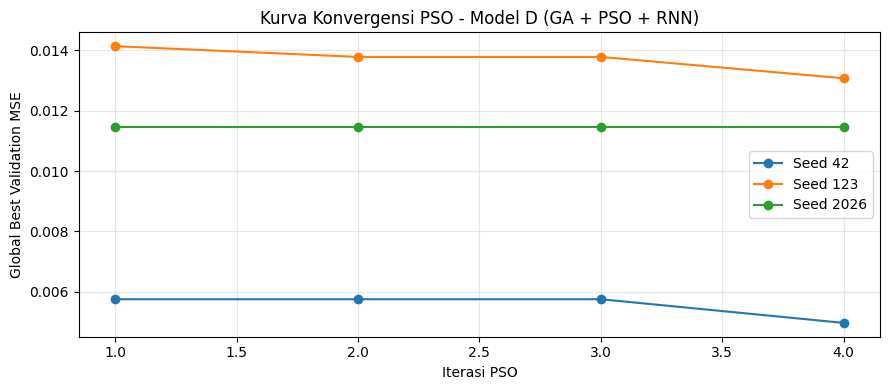

In [5]:
SEEDS = [42, 123, 2026]
all_pso_logs, seed_summary = [], {}

start_pso_time = time.time()
for s in SEEDS:
    g_pos, g_score, df_log = run_pso(seed=s, num_particles=4, iterations=4)
    all_pso_logs.append(df_log)
    seed_summary[s] = {"pos": g_pos, "mse": g_score}
pso_total_time = time.time() - start_pso_time

df_pso_conv = pd.concat(all_pso_logs, ignore_index=True)
df_pso_conv.to_csv("pso_d_convergence.csv", index=False)

scores_list = [seed_summary[s]["mse"] for s in SEEDS]
best_seed = min(seed_summary, key=lambda k: seed_summary[k]["mse"])
best_pos  = seed_summary[best_seed]["pos"]

best_hidden_D = int(round(best_pos[0]))
best_seq_D    = int(round(best_pos[1]))
best_lr_D     = float(10 ** best_pos[2])

print("\n=== RINGKASAN STATISTIK MULTI-SEED PSO (MODEL D) ===")
print(f"Total Waktu PSO : {pso_total_time:.2f} detik")
print(f"Best Val MSE    : {np.min(scores_list):.5f} (Seed {best_seed})")
print(f"Mean Val MSE    : {np.mean(scores_list):.5f}")
print(f"Std Val MSE     : {np.std(scores_list):.5f}")
print(f"Hyperparameter Terbaik -> Hidden: {best_hidden_D} | SeqLen: {best_seq_D} | LR: {best_lr_D:.6f}")

plt.figure(figsize=(9, 4))
for s in SEEDS:
    sub = df_pso_conv[df_pso_conv["Seed"] == s]
    plt.plot(sub["Iterasi"], sub["Global_Best_MSE"], marker="o", label=f"Seed {s}")
plt.title("Kurva Konvergensi PSO - Model D (GA + PSO + RNN)")
plt.xlabel("Iterasi PSO")
plt.ylabel("Global Best Validation MSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("pso_d_convergence.png", dpi=300)
plt.show()


## Tahap 6. Training Final Model D & Evaluasi


--- Memulai Pelatihan Final Model D (GA + PSO + RNN) ---
Epoch 01/5 | Train MSE: 0.00527 | Val MSE: 0.00321 | Val RMSE: 1982.62
Epoch 02/5 | Train MSE: 0.00203 | Val MSE: 0.00236 | Val RMSE: 1711.11
Epoch 03/5 | Train MSE: 0.00175 | Val MSE: 0.00223 | Val RMSE: 1692.03
Epoch 04/5 | Train MSE: 0.00158 | Val MSE: 0.00226 | Val RMSE: 1716.51
Epoch 05/5 | Train MSE: 0.00152 | Val MSE: 0.00217 | Val RMSE: 1693.73

=== EVALUASI AKHIR MODEL D (GA + PSO + RNN) ===
Waktu Training : 9.38 detik
Val  -> MSE: 0.00217 | RMSE: 1693.73 kW | MAE: 1259.56 kW | R2: 0.8815
Test -> MSE: 0.00559 | RMSE: 2651.63 kW | MAE: 2169.14 kW | R2: 0.7350


,Zona,Test RMSE (kW),Test MAE (kW),Test R2
0,Zone 1,3623.57,3329.91,0.6442
1,Zone 2,2161.31,1887.30,0.8513
2,Zone 3,1814.37,1290.20,0.7097



=== TABEL PERBANDINGAN MODEL A, B, DAN D ===


,Model,Fitur,Val RMSE (kW),Val MAE (kW),Val R2,Test RMSE (kW),Test R2,Waktu (detik)
0,Model A (Baseline RNN),9,2990.07,2410.04,0.5422,4904.75,-0.0680,76.78
1,Model B (GA + RNN),10,1510.03,1097.96,0.9189,2277.36,0.8144,73.58
2,Model D (GA + PSO + RNN),10,1693.73,1259.56,0.8815,2651.63,0.7350,9.38


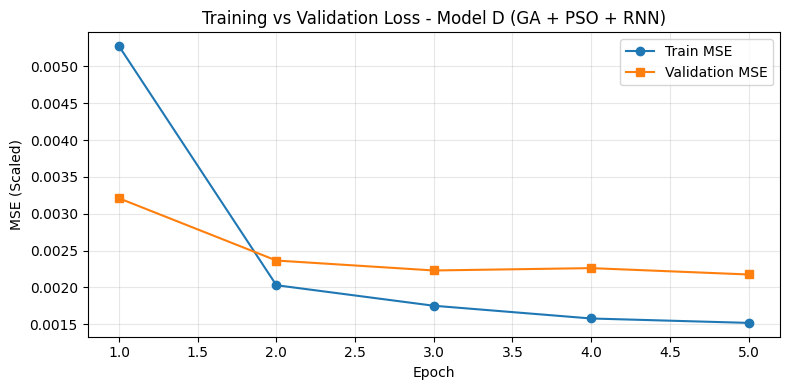

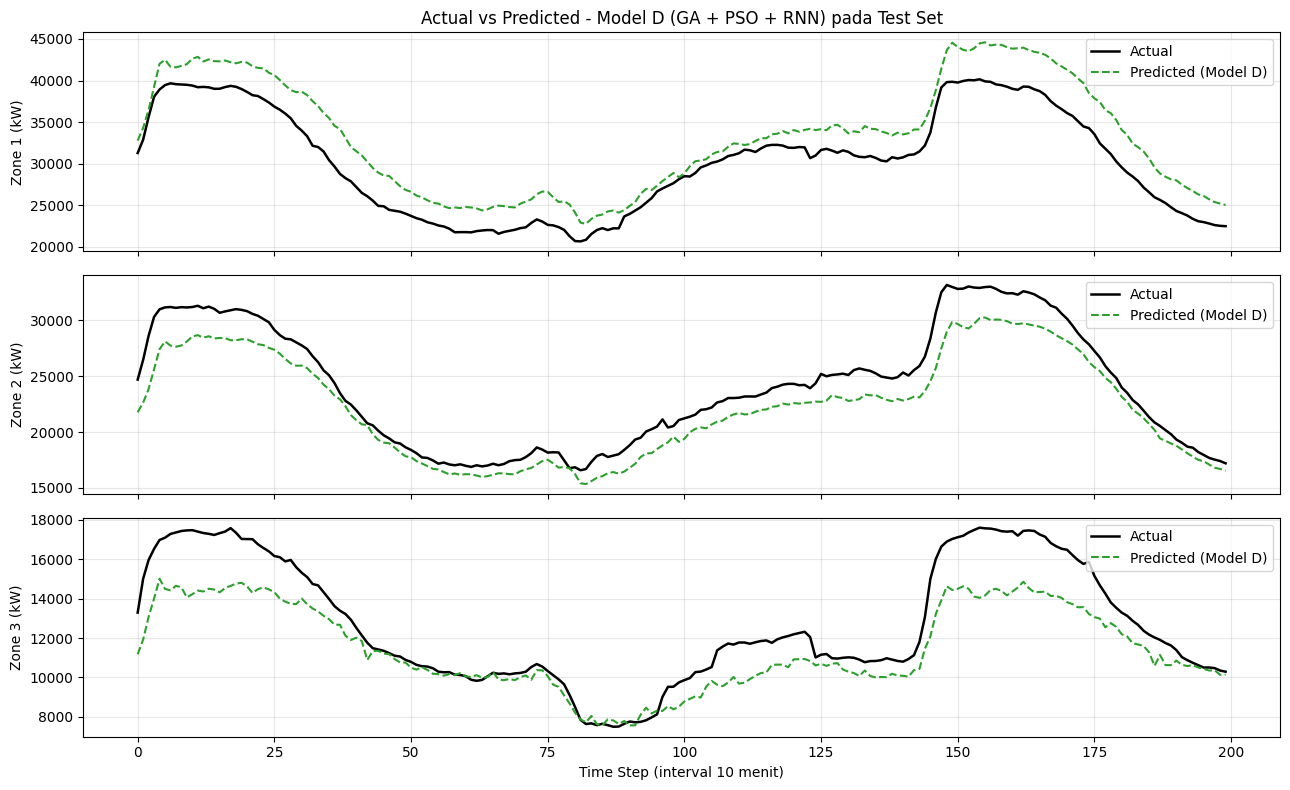

In [6]:
X_tr_D, y_tr_D = create_sequences(X_train_sc, y_train_sc, best_seq_D)
X_va_D, y_va_D = create_sequences(X_val_sc, y_val_sc, best_seq_D)
X_te_D, y_te_D = create_sequences(X_test_sc, y_test_sc, best_seq_D)

train_loader_D = DataLoader(TensorDataset(torch.tensor(X_tr_D), torch.tensor(y_tr_D)), batch_size=128, shuffle=False)
val_loader_D   = DataLoader(TensorDataset(torch.tensor(X_va_D), torch.tensor(y_va_D)), batch_size=128, shuffle=False)
test_loader_D  = DataLoader(TensorDataset(torch.tensor(X_te_D), torch.tensor(y_te_D)), batch_size=128, shuffle=False)

torch.manual_seed(best_seed)
model_D = MultiZoneRNN(input_dim=len(selected_features_ga), hidden_dim=best_hidden_D, output_dim=3).to(device)
criterion_D = nn.MSELoss()
optimizer_D = torch.optim.Adam(model_D.parameters(), lr=best_lr_D)

EPOCHS_FINAL = 5
train_hist, val_hist = [], []
best_val_loss = float("inf")

print("--- Memulai Pelatihan Final Model D (GA + PSO + RNN) ---")
start_time_D = time.time()

for epoch in range(EPOCHS_FINAL):
    model_D.train()
    tr_loss = 0.0
    for xb, yb in train_loader_D:
        xb, yb = xb.to(device), yb.to(device)
        optimizer_D.zero_grad()
        loss = criterion_D(model_D(xb), yb)
        loss.backward()
        optimizer_D.step()
        tr_loss += loss.item()

    avg_tr_loss = tr_loss / len(train_loader_D)
    val_mse_D, val_rmse_D, val_mae_D, val_r2_D, _, _ = evaluate_metrics(model_D, val_loader_D, scaler_y_D)
    train_hist.append(avg_tr_loss)
    val_hist.append(val_mse_D)

    if val_mse_D < best_val_loss:
        best_val_loss = val_mse_D
        torch.save(model_D.state_dict(), "model_D_ga_pso_rnn.pth")

    print(f"Epoch {epoch+1:02d}/{EPOCHS_FINAL} | Train MSE: {avg_tr_loss:.5f} | Val MSE: {val_mse_D:.5f} | Val RMSE: {val_rmse_D:.2f}")

time_D = time.time() - start_time_D

model_D.load_state_dict(torch.load("model_D_ga_pso_rnn.pth", map_location=device))
val_mse_D, val_rmse_D, val_mae_D, val_r2_D, _, _ = evaluate_metrics(model_D, val_loader_D, scaler_y_D)
test_mse_D, test_rmse_D, test_mae_D, test_r2_D, y_act_D, y_pred_D = evaluate_metrics(model_D, test_loader_D, scaler_y_D)

print("\n=== EVALUASI AKHIR MODEL D (GA + PSO + RNN) ===")
print(f"Waktu Training : {time_D:.2f} detik")
print(f"Val  -> MSE: {val_mse_D:.5f} | RMSE: {val_rmse_D:.2f} kW | MAE: {val_mae_D:.2f} kW | R2: {val_r2_D:.4f}")
print(f"Test -> MSE: {test_mse_D:.5f} | RMSE: {test_rmse_D:.2f} kW | MAE: {test_mae_D:.2f} kW | R2: {test_r2_D:.4f}")

# Evaluasi Per Zona
zona_names = ["Zone 1", "Zone 2", "Zone 3"]
per_zona = []
for idx, zn in enumerate(zona_names):
    per_zona.append({
        "Zona": zn,
        "Test RMSE (kW)": round(float(np.sqrt(mean_squared_error(y_act_D[:, idx], y_pred_D[:, idx]))), 2),
        "Test MAE (kW)": round(float(mean_absolute_error(y_act_D[:, idx], y_pred_D[:, idx])), 2),
        "Test R2": round(float(r2_score(y_act_D[:, idx], y_pred_D[:, idx])), 4)
    })
df_per_zona = pd.DataFrame(per_zona)
display(df_per_zona)

# Tabel Perbandingan Model A, B (dari notebook GA kelompok), dan Model D
df_perbandingan = pd.DataFrame([
    {"Model": "Model A (Baseline RNN)", "Fitur": 9, "Val RMSE (kW)": 2990.07, "Val MAE (kW)": 2410.04, "Val R2": 0.5422, "Test RMSE (kW)": 4904.75, "Test R2": -0.0680, "Waktu (detik)": 76.78},
    {"Model": "Model B (GA + RNN)", "Fitur": 10, "Val RMSE (kW)": 1510.03, "Val MAE (kW)": 1097.96, "Val R2": 0.9189, "Test RMSE (kW)": 2277.36, "Test R2": 0.8144, "Waktu (detik)": 73.58},
    {"Model": "Model D (GA + PSO + RNN)", "Fitur": len(selected_features_ga), "Val RMSE (kW)": round(val_rmse_D, 2), "Val MAE (kW)": round(val_mae_D, 2), "Val R2": round(val_r2_D, 4), "Test RMSE (kW)": round(test_rmse_D, 2), "Test R2": round(test_r2_D, 4), "Waktu (detik)": round(time_D, 2)}
])
print("\n=== TABEL PERBANDINGAN MODEL A, B, DAN D ===")
display(df_perbandingan)

# Plot Learning Curve
plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS_FINAL + 1), train_hist, marker="o", label="Train MSE")
plt.plot(range(1, EPOCHS_FINAL + 1), val_hist, marker="s", label="Validation MSE")
plt.title("Training vs Validation Loss - Model D (GA + PSO + RNN)")
plt.xlabel("Epoch")
plt.ylabel("MSE (Scaled)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("model_D_learning_curve.png", dpi=300)
plt.show()

# Plot Actual vs Predicted 3 Zona
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
for idx in range(3):
    axes[idx].plot(y_act_D[:200, idx], label="Actual", color="black", linewidth=1.8)
    axes[idx].plot(y_pred_D[:200, idx], label="Predicted (Model D)", color="tab:green", linestyle="--")
    axes[idx].set_ylabel(f"{zona_names[idx]} (kW)")
    axes[idx].legend(loc="upper right")
    axes[idx].grid(True, alpha=0.3)
axes[0].set_title("Actual vs Predicted - Model D (GA + PSO + RNN) pada Test Set")
axes[2].set_xlabel("Time Step (interval 10 menit)")
plt.tight_layout()
plt.savefig("model_D_actual_vs_pred.png", dpi=300)
plt.show()


## Tahap 7. Simpan Artefak Model & Download ZIP


In [7]:
df_eval_D = pd.DataFrame([{
    "Model": "Model D (GA + PSO + RNN)",
    "Jumlah Fitur": len(selected_features_ga),
    "Hidden Units": best_hidden_D,
    "Seq Length": best_seq_D,
    "Learning Rate": round(best_lr_D, 6),
    "Val MSE": round(val_mse_D, 5),
    "Val RMSE (kW)": round(val_rmse_D, 2),
    "Val MAE (kW)": round(val_mae_D, 2),
    "Val R2": round(val_r2_D, 4),
    "Test MSE": round(test_mse_D, 5),
    "Test RMSE (kW)": round(test_rmse_D, 2),
    "Test MAE (kW)": round(test_mae_D, 2),
    "Test R2": round(test_r2_D, 4),
    "Waktu Training (detik)": round(time_D, 2)
}])
df_eval_D.to_csv("eval_model_D.csv", index=False)
df_per_zona.to_csv("eval_model_D_per_zona.csv", index=False)
df_perbandingan.to_csv("perbandingan_model_A_B_D.csv", index=False)

joblib.dump(scaler_X_D, "scaler_X_D.pkl")
joblib.dump(scaler_y_D, "scaler_y_D.pkl")

with open("model_D_config.json", "w") as f:
    json.dump({
        "selected_features": selected_features_ga,
        "best_seed": int(best_seed),
        "hidden_dim": best_hidden_D,
        "seq_length": best_seq_D,
        "learning_rate": best_lr_D,
        "pso_stats": {
            "best_val_mse": float(np.min(scores_list)),
            "mean_val_mse": float(np.mean(scores_list)),
            "std_val_mse": float(np.std(scores_list))
        }
    }, f, indent=2)

daftar_file = [
    "model_D_ga_pso_rnn.pth",
    "scaler_X_D.pkl",
    "scaler_y_D.pkl",
    "model_D_config.json",
    "pso_d_convergence.csv",
    "pso_d_convergence.png",
    "model_D_learning_curve.png",
    "model_D_actual_vs_pred.png",
    "eval_model_D.csv",
    "eval_model_D_per_zona.csv",
    "perbandingan_model_A_B_D.csv"
]

with zipfile.ZipFile("Hasil_Model_D_GA_PSO_RNN.zip", "w") as zipf:
    for file_name in daftar_file:
        zipf.write(file_name)

print("Semua artefak berhasil dikemas ke 'Hasil_Model_D_GA_PSO_RNN.zip'.")
try:
    from google.colab import files
    files.download("Hasil_Model_D_GA_PSO_RNN.zip")
except ImportError:
    print("Mode non-Colab terdeteksi. File ZIP tersimpan di direktori lokal.")


Semua artefak berhasil dikemas ke 'Hasil_Model_D_GA_PSO_RNN.zip'.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>